✅ Against All Odds — Week 7
Project root: /content/againstallodds

Upload the missing Week 6 model-ready CSV files or a ZIP containing them:
 - nba_model_ready_2021_22_to_2025_26.csv
 - nfl_model_ready_2021_to_2025.csv
 - premier_league_model_ready_2021_22_to_2025_26.csv


Saving New folder.zip to New folder.zip
✅ NBA: 4,852 development rows
✅ NFL: 1,021 development rows
✅ Premier League: 1,480 development rows

EDA summary:
         sport  games start_date   end_date  home_win_rate  mean_abs_elo_diff  mean_abs_form_diff  mean_abs_offense_diff  mean_abs_defense_diff  mean_abs_rest_diff
           NBA   4852 2021-10-22 2025-04-13       0.553586         109.983725            0.302872               4.918227               5.195233            0.604699
           NFL   1021 2021-09-16 2025-01-05       0.544564          65.304852            0.304016               5.850117               4.868521            1.231146
Premier League   1480 2021-08-21 2025-05-25       0.444595          92.164417            0.289662               0.643766               0.530687            1.279730


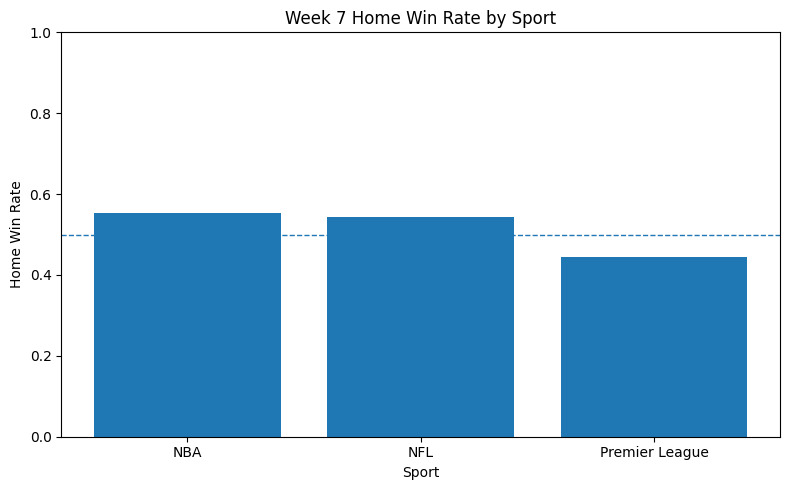

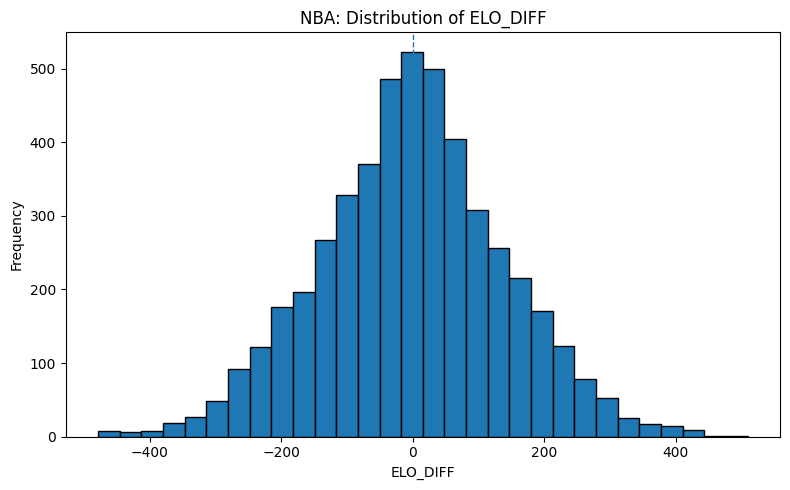

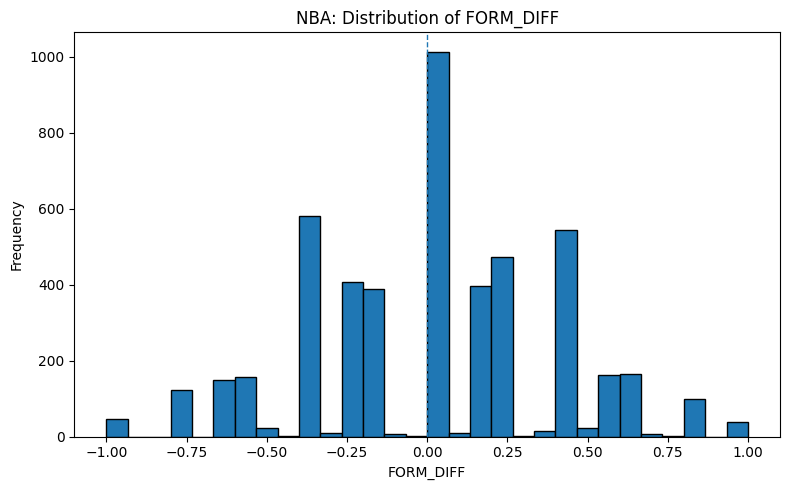

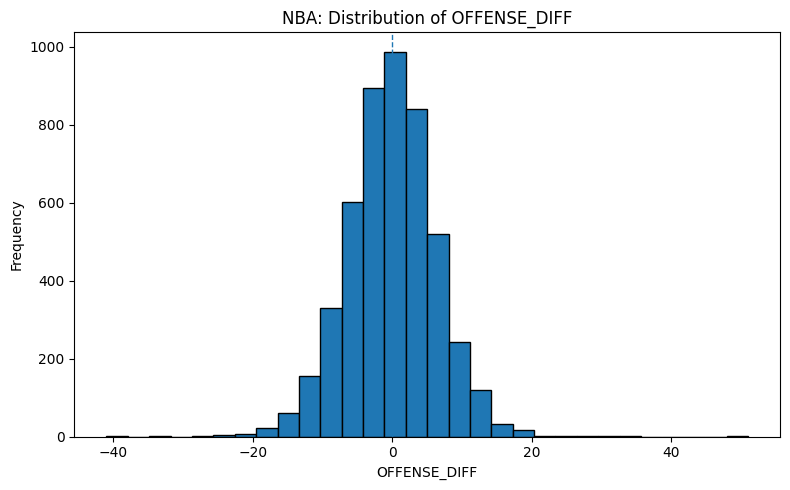

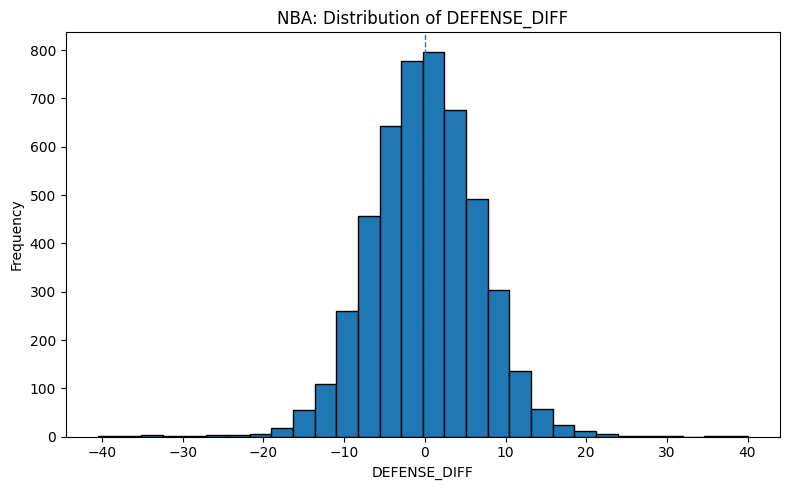

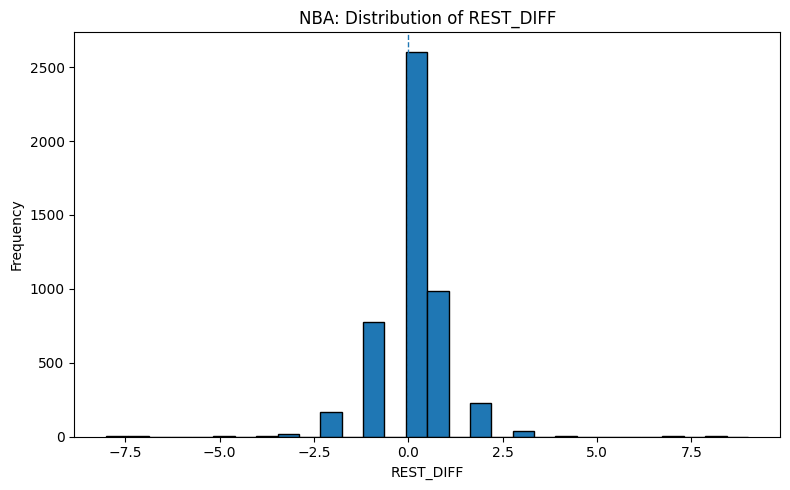

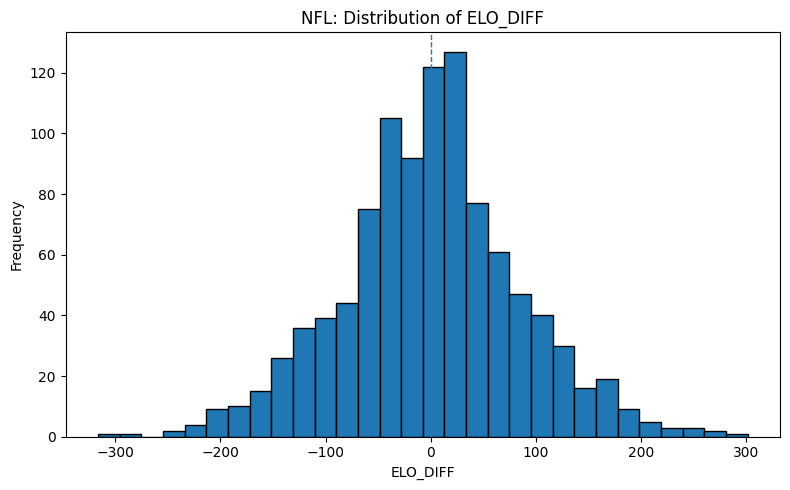

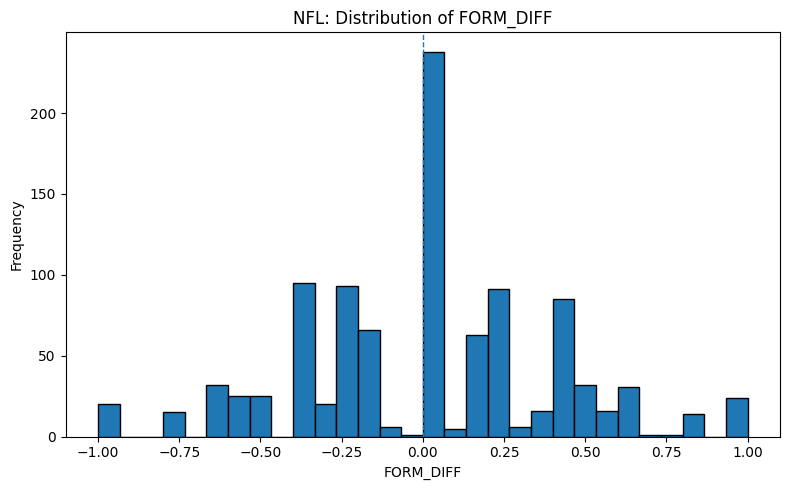

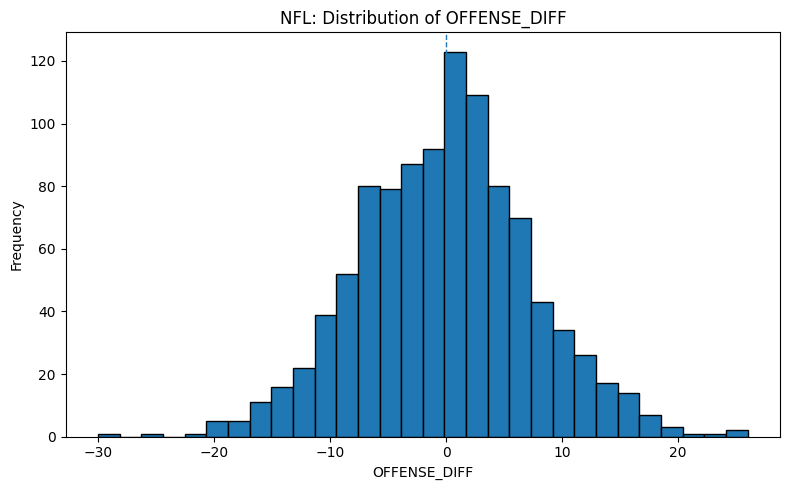

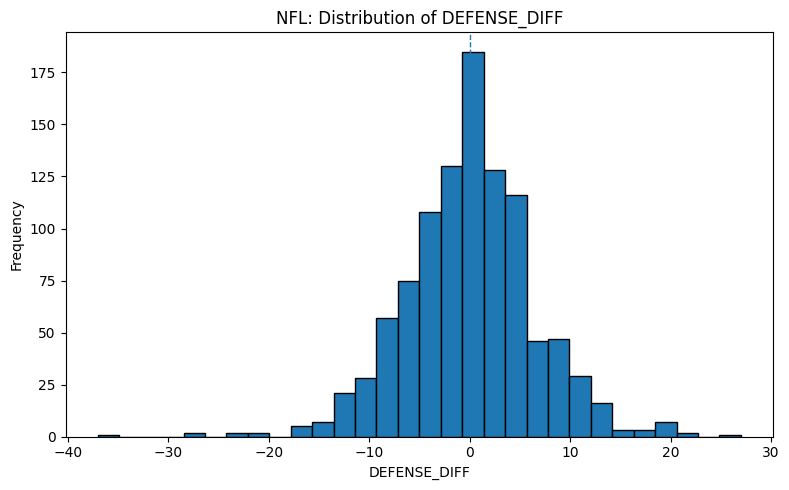

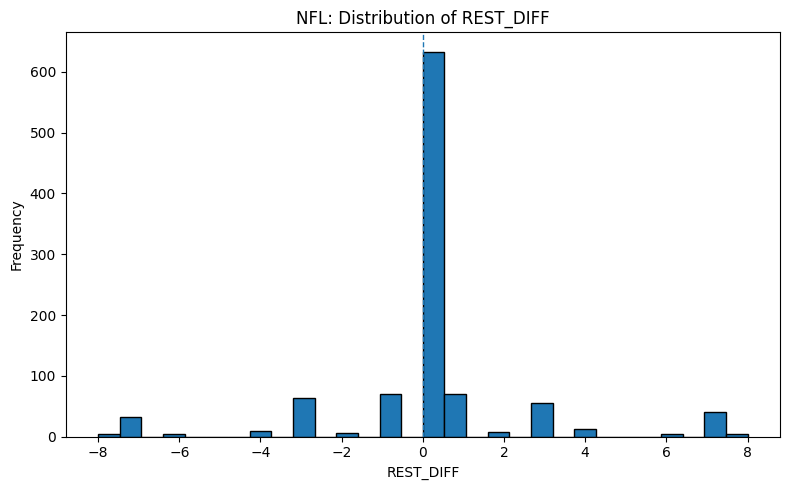

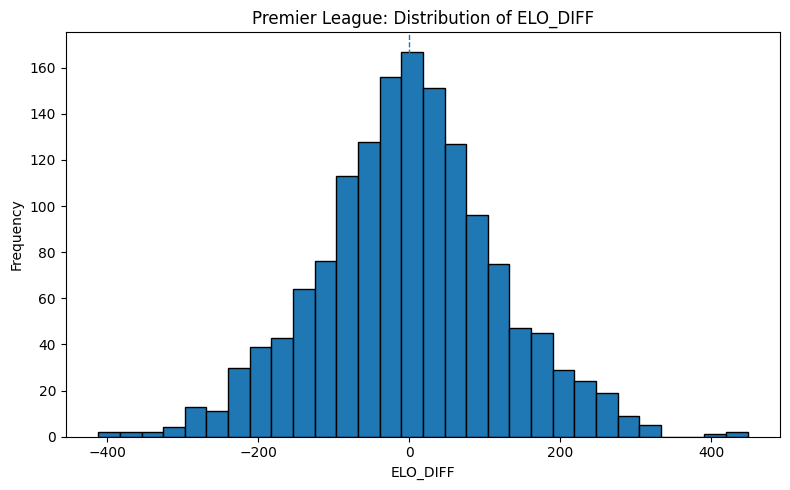

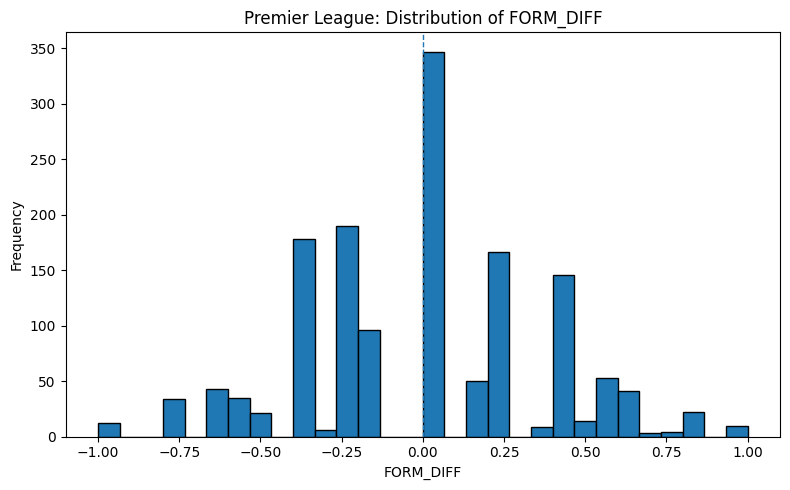

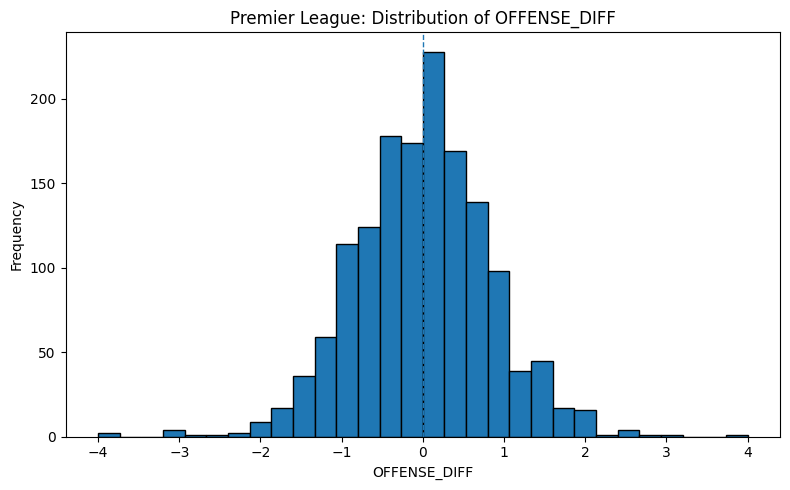

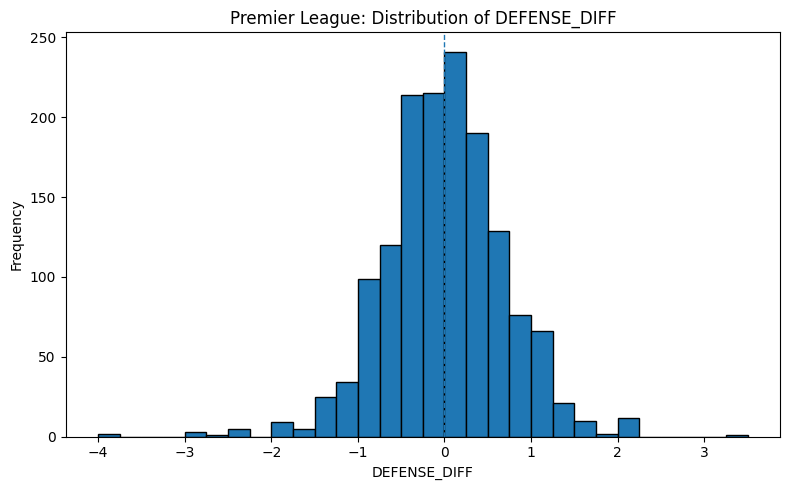

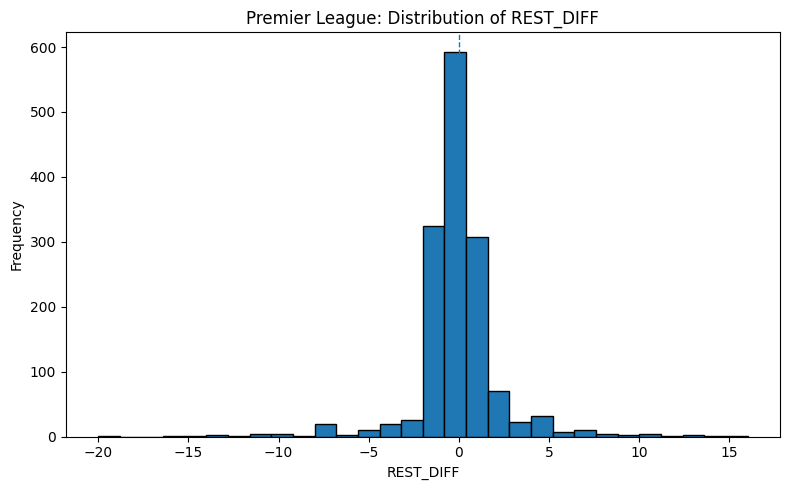

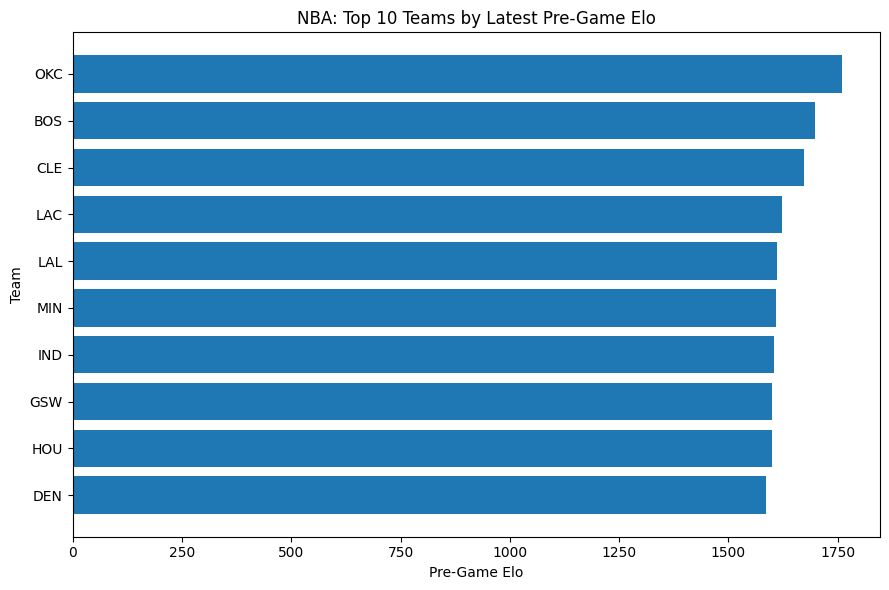

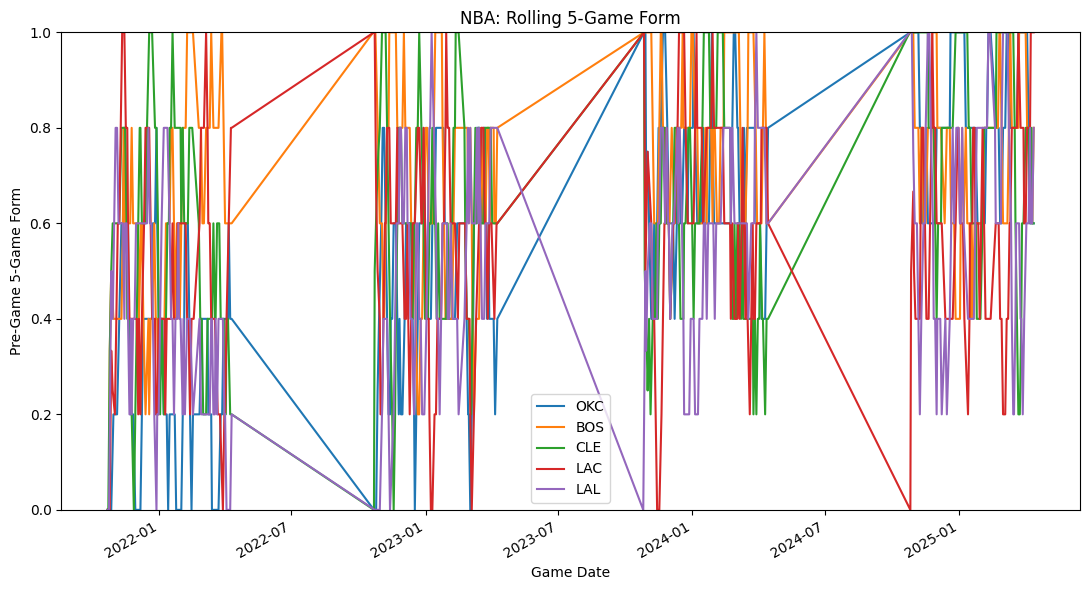

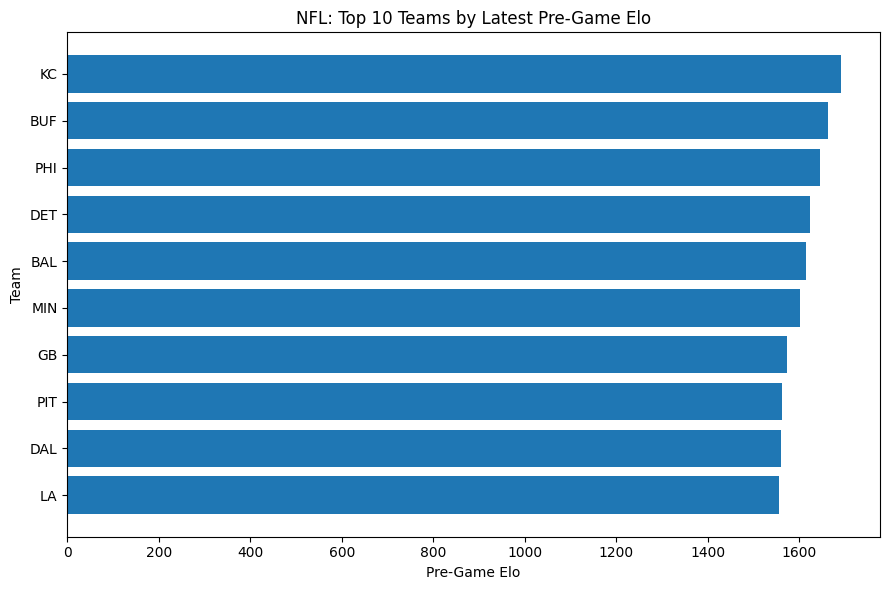

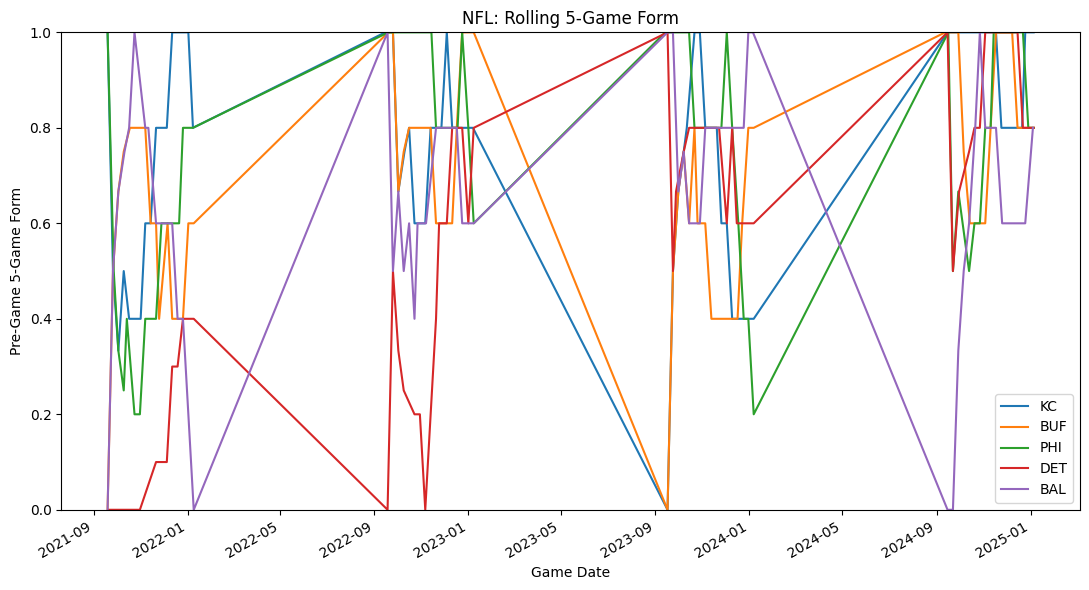

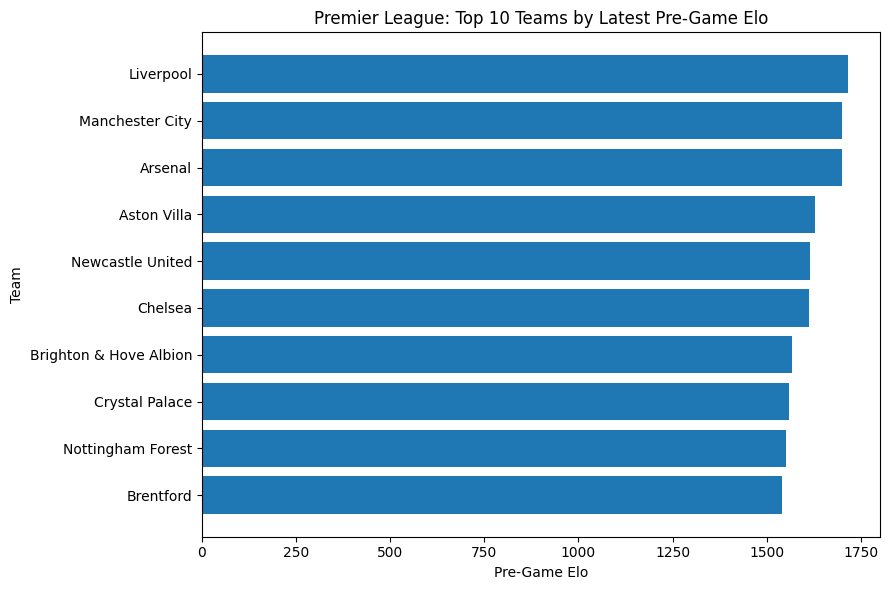

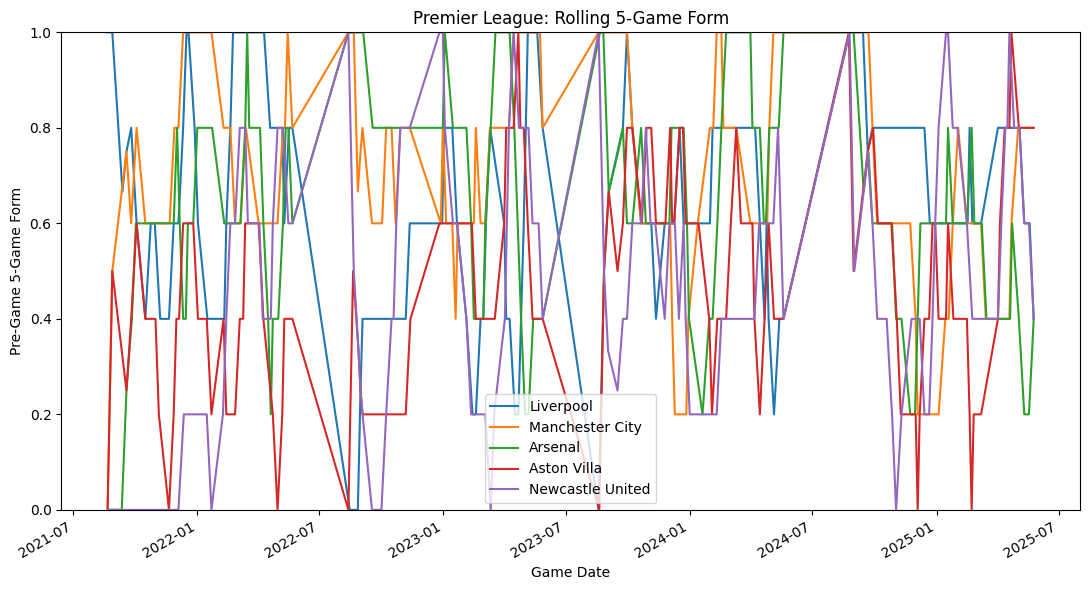

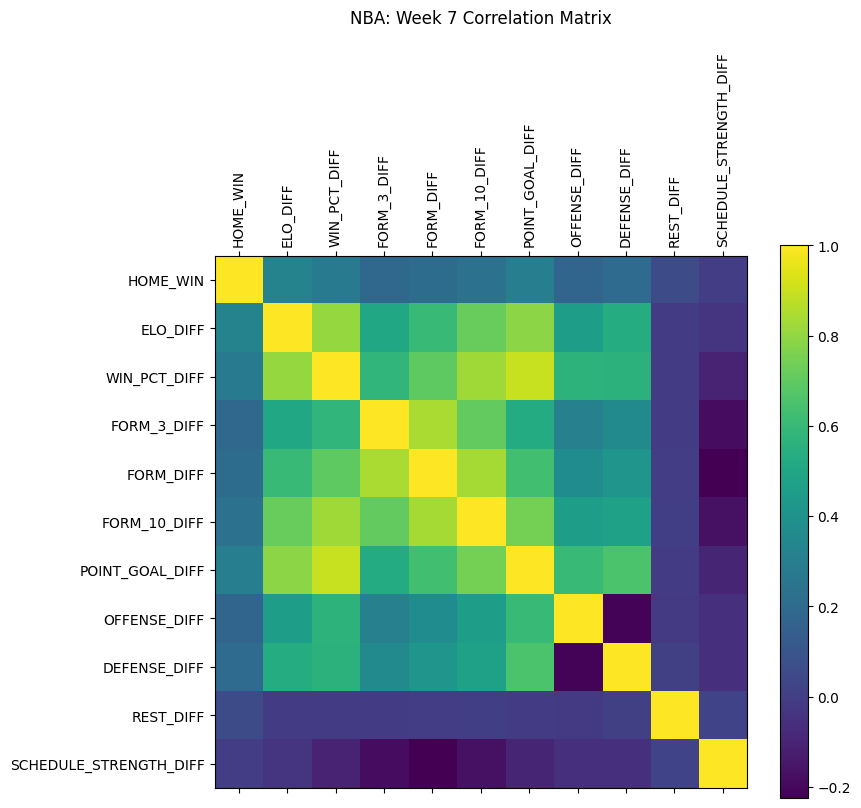

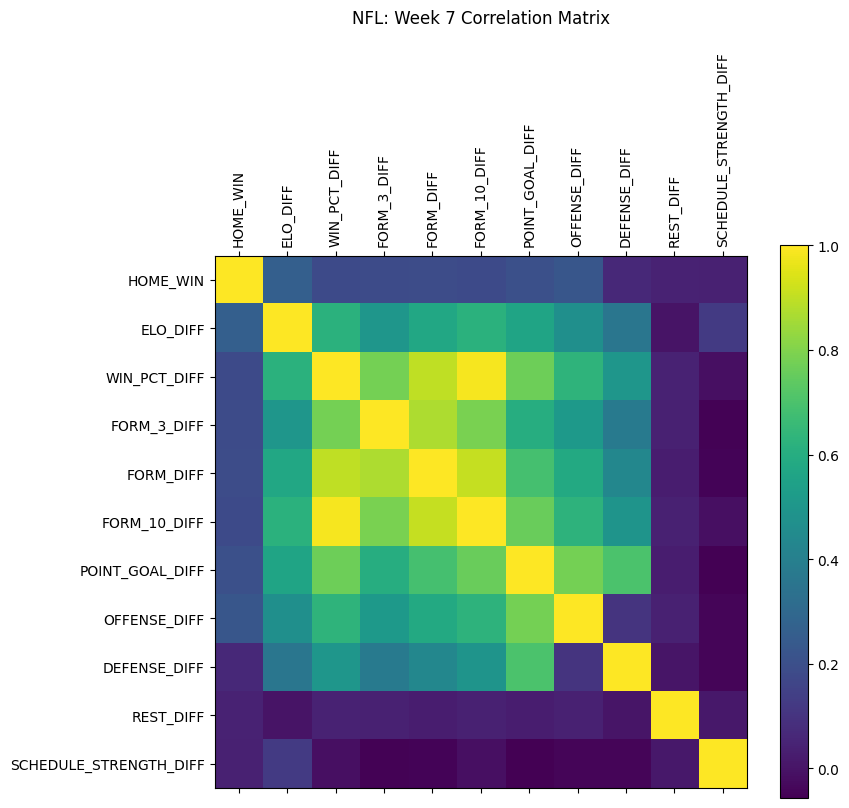

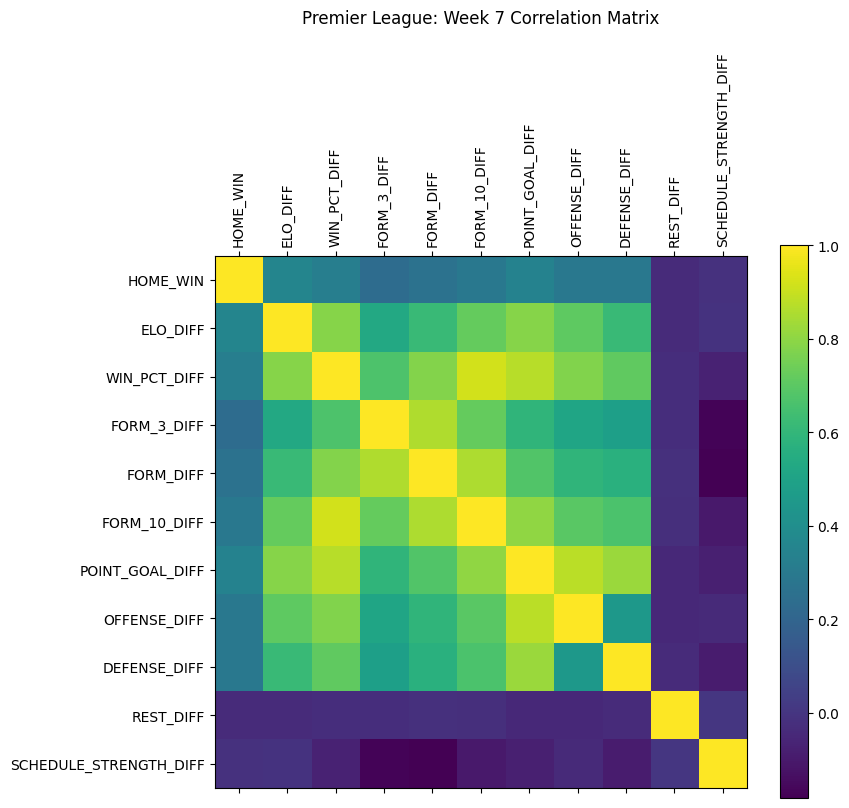


Baseline results:
         sport        data_split         baseline  games  accuracy  precision   recall       f1  true_negative  false_positive  false_negative  true_positive
           NBA WEEK7_DEV_OVERALL Always Home Team   4852  0.553586   0.553586 1.000000 0.712656              0            2166               0           2686
           NBA WEEK7_DEV_OVERALL    Better Record   4852  0.623248   0.673263 0.620625 0.645874           1357             809            1019           1667
           NBA WEEK7_DEV_OVERALL       Higher Elo   4852  0.631080   0.685124 0.617275 0.649432           1404             762            1028           1658
           NFL WEEK7_DEV_OVERALL Always Home Team   1021  0.544564   0.544564 1.000000 0.705136              0             465               0            556
           NFL WEEK7_DEV_OVERALL    Better Record   1021  0.599412   0.623116 0.669065 0.645273            240             225             184            372
           NFL WEEK7_DEV_OVERALL 

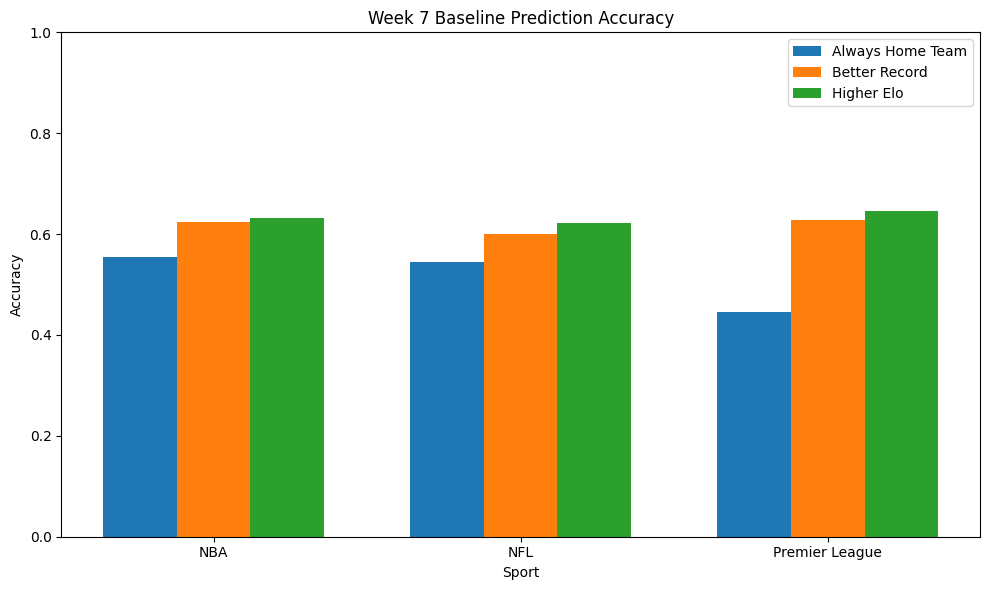

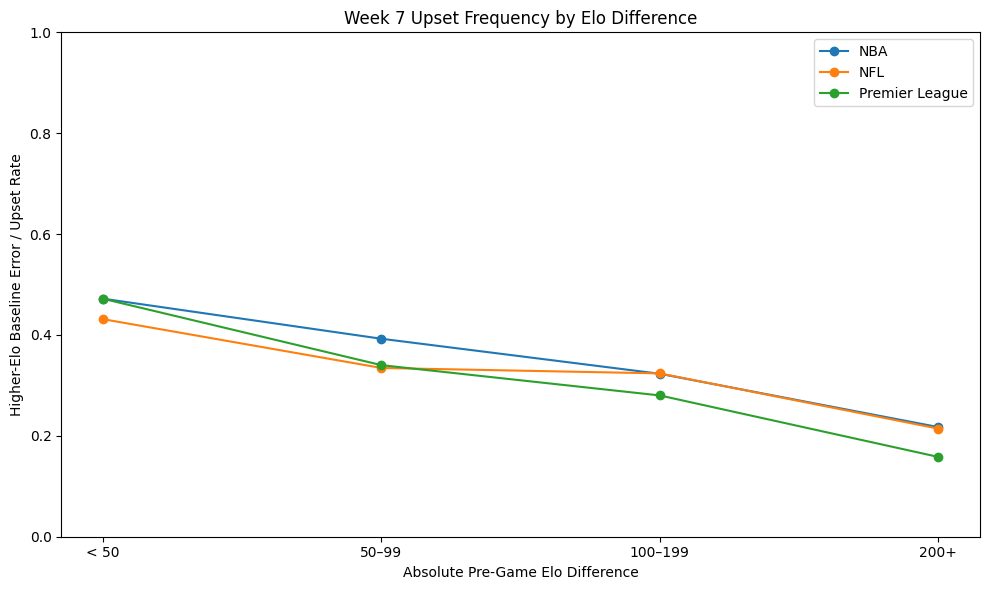


AGAINST ALL ODDS — WEEK 7 COMPLETE
✅ EDA complete
✅ Baselines complete
✅ Upset-frequency analysis complete
✅ Week 7 report and quality checks complete
✅ GitHub upload ZIP: /content/againstallodds/Against_All_Odds_Week7_GitHub_Upload.zip

Push to GitHub:
 - notebooks/08_baseline_models.ipynb
 - docs/week7_eda_and_baseline_report.md
 - docs/week7_README_addition.md
 - results/week7_*.csv
 - figures/week7/*.png

Next: Week 8 — Logistic Regression and Elo.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [2]:
from pathlib import Path
from datetime import datetime, timezone
import sys
import zipfile
import warnings
import shutil

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

warnings.filterwarnings('ignore', category=FutureWarning)
np.random.seed(42)

PROJECT_TITLE = 'Against All Odds'
WEEK_NUMBER = 7
INCLUDE_TEST_IN_WEEK7 = False

EXPECTED_INPUTS = {
    'NBA': 'nba_model_ready_2021_22_to_2025_26.csv',
    'NFL': 'nfl_model_ready_2021_to_2025.csv',
    'Premier League': 'premier_league_model_ready_2021_22_to_2025_26.csv',
}

TEAM_COLUMNS = {
    'NBA': ('home_team_abbr', 'away_team_abbr'),
    'NFL': ('home_team', 'away_team'),
    'Premier League': ('home_team', 'away_team'),
}

REQUIRED_COLUMNS = [
    'game_id', 'game_date', 'data_split', 'HOME_WIN',
    'HOME_ELO_PRE', 'AWAY_ELO_PRE', 'ELO_DIFF',
    'HOME_WIN_PCT_PRE', 'AWAY_WIN_PCT_PRE', 'WIN_PCT_DIFF',
    'HOME_FORM_3', 'AWAY_FORM_3', 'FORM_3_DIFF',
    'HOME_FORM_5', 'AWAY_FORM_5', 'FORM_DIFF',
    'HOME_FORM_10', 'AWAY_FORM_10', 'FORM_10_DIFF',
    'POINT_GOAL_DIFF', 'OFFENSE_DIFF', 'DEFENSE_DIFF', 'REST_DIFF',
]

CORR_FEATURES = [
    'HOME_WIN', 'ELO_DIFF', 'WIN_PCT_DIFF', 'FORM_3_DIFF', 'FORM_DIFF',
    'FORM_10_DIFF', 'POINT_GOAL_DIFF', 'OFFENSE_DIFF', 'DEFENSE_DIFF', 'REST_DIFF',
    'SCHEDULE_STRENGTH_DIFF',
]

DIST_FEATURES = ['ELO_DIFF', 'FORM_DIFF', 'OFFENSE_DIFF', 'DEFENSE_DIFF', 'REST_DIFF']


def running_in_colab():
    return 'google.colab' in sys.modules


def choose_project_root():
    cwd = Path.cwd().resolve()
    candidates = [
        cwd if cwd.name.lower().replace('_', '-') in {'againstallodds', 'against-all-odds'} else None,
        Path('/content/againstallodds'),
        Path('/content/Against-All-Odds'),
        Path('/content/drive/MyDrive/againstallodds'),
        Path('/content/drive/MyDrive/Against-All-Odds'),
    ]
    for candidate in candidates:
        if candidate is not None and candidate.exists():
            return candidate
    return Path('/content/againstallodds') if running_in_colab() else cwd / 'againstallodds'


PROJECT_ROOT = choose_project_root()
MODEL_READY_DIR = PROJECT_ROOT / 'data' / 'model_ready'
FIGURES_DIR = PROJECT_ROOT / 'figures' / 'week7'
RESULTS_DIR = PROJECT_ROOT / 'results'
DOCS_DIR = PROJECT_ROOT / 'docs'
for folder in [MODEL_READY_DIR, FIGURES_DIR, RESULTS_DIR, DOCS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print(f'✅ {PROJECT_TITLE} — Week {WEEK_NUMBER}')
print('Project root:', PROJECT_ROOT)


def search_locations():
    locations = [PROJECT_ROOT, MODEL_READY_DIR, Path('/content'), Path('/content/week7_inputs'), Path.cwd().resolve()]
    return list(dict.fromkeys([p for p in locations if p.exists()]))


def find_exact_file(filename):
    for root in search_locations():
        direct = root / filename
        if direct.exists():
            return direct
    for root in search_locations():
        try:
            matches = list(root.rglob(filename))
        except (PermissionError, OSError):
            matches = []
        if matches:
            return matches[0]
    return None


def resolve_inputs():
    found = {sport: find_exact_file(filename) for sport, filename in EXPECTED_INPUTS.items()}
    missing = [EXPECTED_INPUTS[s] for s, path in found.items() if path is None]
    if missing and running_in_colab():
        print('\nUpload the missing Week 6 model-ready CSV files or a ZIP containing them:')
        for name in missing:
            print(' -', name)
        from google.colab import files
        uploaded = files.upload()
        upload_dir = Path('/content/week7_inputs')
        upload_dir.mkdir(parents=True, exist_ok=True)
        for name, blob in uploaded.items():
            dest = upload_dir / Path(name).name
            dest.write_bytes(blob)
            if zipfile.is_zipfile(dest):
                with zipfile.ZipFile(dest, 'r') as z:
                    z.extractall(upload_dir)
        found = {sport: find_exact_file(filename) for sport, filename in EXPECTED_INPUTS.items()}
    missing = [EXPECTED_INPUTS[s] for s, path in found.items() if path is None]
    if missing:
        raise FileNotFoundError('Week 7 needs these Week 6 files:\n' + '\n'.join(f' - {x}' for x in missing))
    return found


INPUT_PATHS = resolve_inputs()


def load_dataset(path):
    return pd.read_csv(path, dtype={'game_id': 'string'}, parse_dates=['game_date'])


datasets = {
    'NBA': load_dataset(INPUT_PATHS['NBA']),
    'NFL': load_dataset(INPUT_PATHS['NFL']),
    'Premier League': load_dataset(INPUT_PATHS['Premier League']),
}

for sport, df in datasets.items():
    home_col, away_col = TEAM_COLUMNS[sport]
    missing = [c for c in REQUIRED_COLUMNS + [home_col, away_col] if c not in df.columns]
    if missing:
        raise ValueError(f'{sport} missing required columns: {missing}')
    df['data_split'] = df['data_split'].astype('string').str.upper().str.strip()
    df['HOME_WIN'] = pd.to_numeric(df['HOME_WIN'], errors='coerce')
    if not df['HOME_WIN'].dropna().isin([0, 1]).all():
        raise ValueError(f'{sport}: HOME_WIN must be binary.')
    df.sort_values(['game_date', 'game_id'], inplace=True, kind='stable')
    df.reset_index(drop=True, inplace=True)


def week7_subset(df):
    if INCLUDE_TEST_IN_WEEK7:
        return df.copy()
    if {'TRAIN', 'VALIDATION'} & set(df['data_split'].dropna().unique()):
        return df[df['data_split'].isin(['TRAIN', 'VALIDATION'])].copy()
    return df[df['data_split'].ne('TEST')].copy()


analysis_data = {sport: week7_subset(df) for sport, df in datasets.items()}
for sport, df in analysis_data.items():
    if df.empty:
        raise ValueError(f'{sport}: no Week 7 analysis rows.')
    print(f'✅ {sport}: {len(df):,} development rows')

# -------------------------------------------------------------------
# 1. Basic EDA summary
# -------------------------------------------------------------------
eda_summary = pd.DataFrame([
    {
        'sport': sport,
        'games': len(df),
        'start_date': df['game_date'].min(),
        'end_date': df['game_date'].max(),
        'home_win_rate': df['HOME_WIN'].mean(),
        'mean_abs_elo_diff': df['ELO_DIFF'].abs().mean(),
        'mean_abs_form_diff': df['FORM_DIFF'].abs().mean(),
        'mean_abs_offense_diff': df['OFFENSE_DIFF'].abs().mean(),
        'mean_abs_defense_diff': df['DEFENSE_DIFF'].abs().mean(),
        'mean_abs_rest_diff': df['REST_DIFF'].abs().mean(),
    }
    for sport, df in analysis_data.items()
])
EDA_SUMMARY_PATH = RESULTS_DIR / 'week7_eda_dataset_summary.csv'
eda_summary.to_csv(EDA_SUMMARY_PATH, index=False)
print('\nEDA summary:')
print(eda_summary.to_string(index=False))

# -------------------------------------------------------------------
# 2. Home-vs-away comparison
# -------------------------------------------------------------------
home_rows = []
for sport, df in analysis_data.items():
    groups = [('WEEK7_DEV_OVERALL', df)] + [(str(k), g) for k, g in df.groupby('data_split')]
    for split_name, g in groups:
        rate = float(g['HOME_WIN'].mean())
        home_rows.append({
            'sport': sport,
            'data_split': split_name,
            'games': len(g),
            'home_wins': int(g['HOME_WIN'].sum()),
            'home_win_rate': rate,
            'non_home_win_rate': 1 - rate,
        })
home_summary = pd.DataFrame(home_rows)
HOME_SUMMARY_PATH = RESULTS_DIR / 'week7_home_vs_away_summary.csv'
home_summary.to_csv(HOME_SUMMARY_PATH, index=False)

plot_df = home_summary[home_summary['data_split'].eq('WEEK7_DEV_OVERALL')]
fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(plot_df['sport'], plot_df['home_win_rate'])
ax.axhline(0.5, linestyle='--', linewidth=1)
ax.set_title('Week 7 Home Win Rate by Sport')
ax.set_xlabel('Sport')
ax.set_ylabel('Home Win Rate')
ax.set_ylim(0, 1)
fig.tight_layout()
HOME_FIG = FIGURES_DIR / 'week7_home_win_rate_by_sport.png'
fig.savefig(HOME_FIG, dpi=160, bbox_inches='tight')
plt.show()
plt.close(fig)

# -------------------------------------------------------------------
# 3. Distribution plots
# -------------------------------------------------------------------
distribution_files = []
for sport, df in analysis_data.items():
    safe = sport.lower().replace(' ', '_')
    for feature in DIST_FEATURES:
        values = pd.to_numeric(df[feature], errors='coerce').dropna()
        if values.empty:
            continue
        fig, ax = plt.subplots(figsize=(8, 5))
        ax.hist(values, bins=30, edgecolor='black')
        ax.axvline(0, linestyle='--', linewidth=1)
        ax.set_title(f'{sport}: Distribution of {feature}')
        ax.set_xlabel(feature)
        ax.set_ylabel('Frequency')
        fig.tight_layout()
        path = FIGURES_DIR / f'{safe}_{feature.lower()}_distribution.png'
        fig.savefig(path, dpi=160, bbox_inches='tight')
        plt.show()
        plt.close(fig)
        distribution_files.append(path)

# -------------------------------------------------------------------
# 4. Team-performance and rolling-form tables/graphs
# -------------------------------------------------------------------
def make_team_long(df, sport):
    home_col, away_col = TEAM_COLUMNS[sport]
    home = pd.DataFrame({
        'sport': sport, 'game_id': df['game_id'], 'game_date': df['game_date'],
        'data_split': df['data_split'], 'team': df[home_col], 'opponent': df[away_col],
        'is_home': 1, 'PRE_GAME_ELO': df['HOME_ELO_PRE'],
        'PRE_GAME_WIN_PCT': df['HOME_WIN_PCT_PRE'], 'FORM_5': df['HOME_FORM_5'],
    })
    away = pd.DataFrame({
        'sport': sport, 'game_id': df['game_id'], 'game_date': df['game_date'],
        'data_split': df['data_split'], 'team': df[away_col], 'opponent': df[home_col],
        'is_home': 0, 'PRE_GAME_ELO': df['AWAY_ELO_PRE'],
        'PRE_GAME_WIN_PCT': df['AWAY_WIN_PCT_PRE'], 'FORM_5': df['AWAY_FORM_5'],
    })
    return pd.concat([home, away], ignore_index=True).sort_values(['team', 'game_date', 'game_id'])

team_long = {sport: make_team_long(df, sport) for sport, df in analysis_data.items()}
latest_frames = []
team_graphs = []
form_graphs = []
for sport, long_df in team_long.items():
    latest = long_df.groupby('team', as_index=False).tail(1).copy()
    latest['sport'] = sport
    latest_frames.append(latest[['sport', 'team', 'game_date', 'PRE_GAME_ELO', 'PRE_GAME_WIN_PCT', 'FORM_5']])

    top10 = latest.sort_values('PRE_GAME_ELO', ascending=False).head(10).sort_values('PRE_GAME_ELO')
    fig, ax = plt.subplots(figsize=(9, 6))
    ax.barh(top10['team'], top10['PRE_GAME_ELO'])
    ax.set_title(f'{sport}: Top 10 Teams by Latest Pre-Game Elo')
    ax.set_xlabel('Pre-Game Elo')
    ax.set_ylabel('Team')
    fig.tight_layout()
    safe = sport.lower().replace(' ', '_')
    path = FIGURES_DIR / f'{safe}_team_performance_latest_elo.png'
    fig.savefig(path, dpi=160, bbox_inches='tight')
    plt.show()
    plt.close(fig)
    team_graphs.append(path)

    selected = latest.sort_values('PRE_GAME_ELO', ascending=False).head(5)['team'].tolist()
    fig, ax = plt.subplots(figsize=(11, 6))
    for team in selected:
        g = long_df[long_df['team'].eq(team)].sort_values('game_date')
        ax.plot(g['game_date'], g['FORM_5'], label=team)
    ax.set_title(f'{sport}: Rolling 5-Game Form')
    ax.set_xlabel('Game Date')
    ax.set_ylabel('Pre-Game 5-Game Form')
    ax.set_ylim(0, 1)
    ax.legend()
    fig.autofmt_xdate()
    fig.tight_layout()
    path = FIGURES_DIR / f'{safe}_rolling_form_top5_teams.png'
    fig.savefig(path, dpi=160, bbox_inches='tight')
    plt.show()
    plt.close(fig)
    form_graphs.append(path)

team_performance = pd.concat(latest_frames, ignore_index=True)
TEAM_PERFORMANCE_PATH = RESULTS_DIR / 'week7_team_performance_summary.csv'
team_performance.to_csv(TEAM_PERFORMANCE_PATH, index=False)

# -------------------------------------------------------------------
# 5. Correlation analysis
# -------------------------------------------------------------------
correlation_paths = []
correlation_figures = []
for sport, df in analysis_data.items():
    available = [c for c in CORR_FEATURES if c in df.columns]
    corr = df[available].apply(pd.to_numeric, errors='coerce').corr()
    safe = sport.lower().replace(' ', '_')
    csv_path = RESULTS_DIR / f'week7_{safe}_correlation_matrix.csv'
    corr.to_csv(csv_path)
    correlation_paths.append(csv_path)

    fig, ax = plt.subplots(figsize=(9, 8))
    image = ax.matshow(corr.values)
    ax.set_xticks(range(len(corr.columns)))
    ax.set_yticks(range(len(corr.index)))
    ax.set_xticklabels(corr.columns, rotation=90)
    ax.set_yticklabels(corr.index)
    ax.set_title(f'{sport}: Week 7 Correlation Matrix', pad=20)
    fig.colorbar(image, ax=ax)
    fig.tight_layout()
    fig_path = FIGURES_DIR / f'{safe}_correlation_matrix.png'
    fig.savefig(fig_path, dpi=160, bbox_inches='tight')
    plt.show()
    plt.close(fig)
    correlation_figures.append(fig_path)

# -------------------------------------------------------------------
# 6. Baseline predictions
# -------------------------------------------------------------------
baseline_frames = {}
for sport, df in analysis_data.items():
    out = df.copy()
    out['PRED_HOME_TEAM'] = 1
    out['PRED_BETTER_RECORD'] = out['HOME_WIN_PCT_PRE'].ge(out['AWAY_WIN_PCT_PRE']).astype('int8')
    out['PRED_HIGHER_ELO'] = out['HOME_ELO_PRE'].ge(out['AWAY_ELO_PRE']).astype('int8')
    out['ELO_BASELINE_UPSET'] = out['PRED_HIGHER_ELO'].ne(out['HOME_WIN']).astype('int8')
    out['RECORD_BASELINE_UPSET'] = out['PRED_BETTER_RECORD'].ne(out['HOME_WIN']).astype('int8')
    baseline_frames[sport] = out

BASELINES = {
    'Always Home Team': 'PRED_HOME_TEAM',
    'Better Record': 'PRED_BETTER_RECORD',
    'Higher Elo': 'PRED_HIGHER_ELO',
}


def evaluate(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return {
        'accuracy': accuracy_score(y_true, y_pred),
        'precision': precision_score(y_true, y_pred, zero_division=0),
        'recall': recall_score(y_true, y_pred, zero_division=0),
        'f1': f1_score(y_true, y_pred, zero_division=0),
        'true_negative': int(tn), 'false_positive': int(fp),
        'false_negative': int(fn), 'true_positive': int(tp),
    }

baseline_rows = []
for sport, df in baseline_frames.items():
    groups = [('WEEK7_DEV_OVERALL', df)] + [(str(k), g) for k, g in df.groupby('data_split')]
    for split_name, g in groups:
        y_true = g['HOME_WIN'].astype(int)
        for baseline_name, col in BASELINES.items():
            metrics = evaluate(y_true, g[col].astype(int))
            baseline_rows.append({'sport': sport, 'data_split': split_name, 'baseline': baseline_name, 'games': len(g), **metrics})

baseline_results = pd.DataFrame(baseline_rows)
BASELINE_RESULTS_PATH = RESULTS_DIR / 'week7_baseline_results.csv'
baseline_results.to_csv(BASELINE_RESULTS_PATH, index=False)
print('\nBaseline results:')
print(baseline_results[baseline_results['data_split'].eq('WEEK7_DEV_OVERALL')].to_string(index=False))

plot_df = baseline_results[baseline_results['data_split'].eq('WEEK7_DEV_OVERALL')]
sports_order = ['NBA', 'NFL', 'Premier League']
baseline_order = ['Always Home Team', 'Better Record', 'Higher Elo']
x = np.arange(len(sports_order))
width = 0.24
fig, ax = plt.subplots(figsize=(10, 6))
for i, baseline in enumerate(baseline_order):
    values = [float(plot_df[(plot_df['sport'].eq(s)) & (plot_df['baseline'].eq(baseline))]['accuracy'].iloc[0]) for s in sports_order]
    ax.bar(x + (i - 1) * width, values, width=width, label=baseline)
ax.set_xticks(x)
ax.set_xticklabels(sports_order)
ax.set_ylim(0, 1)
ax.set_xlabel('Sport')
ax.set_ylabel('Accuracy')
ax.set_title('Week 7 Baseline Prediction Accuracy')
ax.legend()
fig.tight_layout()
BASELINE_FIG = FIGURES_DIR / 'week7_baseline_accuracy_comparison.png'
fig.savefig(BASELINE_FIG, dpi=160, bbox_inches='tight')
plt.show()
plt.close(fig)

# -------------------------------------------------------------------
# 7. Upset-frequency analysis
# -------------------------------------------------------------------
upset_rows = []
strength_rows = []
for sport, df in baseline_frames.items():
    upset_rows.append({
        'sport': sport,
        'games': len(df),
        'higher_elo_baseline_error_rate': df['ELO_BASELINE_UPSET'].mean(),
        'better_record_baseline_error_rate': df['RECORD_BASELINE_UPSET'].mean(),
    })
    temp = df.copy()
    temp['ABS_ELO_DIFF'] = temp['ELO_DIFF'].abs()
    temp['ELO_STRENGTH_BUCKET'] = pd.cut(
        temp['ABS_ELO_DIFF'],
        bins=[-np.inf, 50, 100, 200, np.inf],
        labels=['< 50', '50–99', '100–199', '200+'],
        right=False,
    )
    summary = temp.groupby('ELO_STRENGTH_BUCKET', observed=False).agg(
        games=('game_id', 'count'),
        elo_upset_rate=('ELO_BASELINE_UPSET', 'mean'),
    ).reset_index()
    summary['sport'] = sport
    strength_rows.append(summary)

upset_frequency = pd.DataFrame(upset_rows)
elo_upset_by_strength = pd.concat(strength_rows, ignore_index=True)
UPSET_PATH = RESULTS_DIR / 'week7_upset_frequency.csv'
UPSET_STRENGTH_PATH = RESULTS_DIR / 'week7_elo_upset_by_strength.csv'
upset_frequency.to_csv(UPSET_PATH, index=False)
elo_upset_by_strength.to_csv(UPSET_STRENGTH_PATH, index=False)

fig, ax = plt.subplots(figsize=(10, 6))
for sport in ['NBA', 'NFL', 'Premier League']:
    g = elo_upset_by_strength[elo_upset_by_strength['sport'].eq(sport)]
    ax.plot(g['ELO_STRENGTH_BUCKET'].astype(str), g['elo_upset_rate'], marker='o', label=sport)
ax.set_ylim(0, 1)
ax.set_xlabel('Absolute Pre-Game Elo Difference')
ax.set_ylabel('Higher-Elo Baseline Error / Upset Rate')
ax.set_title('Week 7 Upset Frequency by Elo Difference')
ax.legend()
fig.tight_layout()
UPSET_FIG = FIGURES_DIR / 'week7_elo_upset_frequency.png'
fig.savefig(UPSET_FIG, dpi=160, bbox_inches='tight')
plt.show()
plt.close(fig)

# -------------------------------------------------------------------
# 8. Documentation and quality checks
# -------------------------------------------------------------------
overall = baseline_results[baseline_results['data_split'].eq('WEEK7_DEV_OVERALL')].sort_values(['sport', 'accuracy'], ascending=[True, False])
best = overall.groupby('sport', as_index=False).first()
best_text = '\n'.join(f'- {r.sport}: {r.baseline} (accuracy = {r.accuracy:.3f})' for r in best.itertuples(index=False))
home_text = '\n'.join(f'- {r.sport}: {r.home_win_rate:.3f}' for r in home_summary[home_summary['data_split'].eq('WEEK7_DEV_OVERALL')].itertuples(index=False))

report = f'''# Against All Odds — Week 7 EDA and Baseline Report

Generated: {datetime.now(timezone.utc).isoformat(timespec='seconds')}

## Week 7 work completed
- Team-performance graphs
- Distribution plots
- Rolling-form graphs
- Correlation analysis
- Home-vs-away comparisons
- Upset-frequency analysis
- Baselines: home team, better record, higher Elo

## Home-win rates
{home_text}

## Best development baseline by sport
{best_text}

## Upset-frequency definition
For this Week 7 descriptive analysis, an Elo upset/error means the higher-Elo baseline did not match the binary HOME_WIN outcome. This is not yet the final Against All Odds upset-risk model.

## Test-set rule
The TEST split was {'included' if INCLUDE_TEST_IN_WEEK7 else 'held out'} during this Week 7 development analysis.

## Next step
Week 8: Logistic Regression and Elo.
'''
WEEK7_REPORT_PATH = DOCS_DIR / 'week7_eda_and_baseline_report.md'
WEEK7_REPORT_PATH.write_text(report, encoding='utf-8')

readme_addition = '''## Week 7 — Exploratory Data Analysis and Baselines

Completed exploratory analysis of the NBA, NFL, and Premier League model-ready datasets. The analysis included team-performance graphs, feature distributions, rolling-form trends, correlation analysis, home-vs-away comparisons, and upset-frequency analysis. Three simple baselines were evaluated: always predicting the home team, choosing the team with the better record, and choosing the team with the higher Elo rating. These results provide a reference point for the logistic regression and Elo modeling stage.
'''
WEEK7_README_PATH = DOCS_DIR / 'week7_README_addition.md'
WEEK7_README_PATH.write_text(readme_addition, encoding='utf-8')

quality = {
    'all_three_sports_loaded': set(datasets) == {'NBA', 'NFL', 'Premier League'},
    'all_analysis_datasets_nonempty': all(len(df) > 0 for df in analysis_data.values()),
    'home_win_binary': all(df['HOME_WIN'].isin([0, 1]).all() for df in analysis_data.values()),
    'three_baselines_present': set(baseline_results['baseline'].unique()) == set(BASELINES),
    'test_held_out_by_default': INCLUDE_TEST_IN_WEEK7 or all('TEST' not in set(df['data_split'].dropna()) for df in analysis_data.values()),
}
week7_quality = pd.DataFrame([{'check': k, 'passed': bool(v)} for k, v in quality.items()])
WEEK7_QUALITY_PATH = RESULTS_DIR / 'week7_quality_report.csv'
week7_quality.to_csv(WEEK7_QUALITY_PATH, index=False)
if not week7_quality['passed'].all():
    raise RuntimeError('Week 7 quality checks failed.')

# -------------------------------------------------------------------
# 9. GitHub upload package
# -------------------------------------------------------------------
runtime_files = [
    EDA_SUMMARY_PATH, HOME_SUMMARY_PATH, TEAM_PERFORMANCE_PATH,
    BASELINE_RESULTS_PATH, UPSET_PATH, UPSET_STRENGTH_PATH,
    WEEK7_QUALITY_PATH, WEEK7_REPORT_PATH, WEEK7_README_PATH,
    HOME_FIG, BASELINE_FIG, UPSET_FIG,
] + distribution_files + team_graphs + form_graphs + correlation_paths + correlation_figures
runtime_files = list(dict.fromkeys(runtime_files))

WEEK7_ZIP = PROJECT_ROOT / 'Against_All_Odds_Week7_GitHub_Upload.zip'
if WEEK7_ZIP.exists():
    WEEK7_ZIP.unlink()
with zipfile.ZipFile(WEEK7_ZIP, 'w', compression=zipfile.ZIP_DEFLATED) as archive:
    for path in runtime_files:
        if path.exists():
            archive.write(path, arcname=path.relative_to(PROJECT_ROOT))
    push_list = '''AGAINST ALL ODDS — WEEK 7 GITHUB PUSH LIST

notebooks/
  08_baseline_models.ipynb

docs/
  week7_eda_and_baseline_report.md
  week7_README_addition.md

results/
  week7_eda_dataset_summary.csv
  week7_home_vs_away_summary.csv
  week7_team_performance_summary.csv
  week7_baseline_results.csv
  week7_upset_frequency.csv
  week7_elo_upset_by_strength.csv
  week7_quality_report.csv
  week7_nba_correlation_matrix.csv
  week7_nfl_correlation_matrix.csv
  week7_premier_league_correlation_matrix.csv

figures/week7/
  Upload all generated PNG files.

Also update README.md using docs/week7_README_addition.md.
'''
    temp = Path('/content/WEEK7_GITHUB_PUSH_LIST.txt') if running_in_colab() else PROJECT_ROOT / 'WEEK7_GITHUB_PUSH_LIST.txt'
    temp.write_text(push_list, encoding='utf-8')
    archive.write(temp, arcname='WEEK7_GITHUB_PUSH_LIST.txt')

print('\n' + '=' * 78)
print('AGAINST ALL ODDS — WEEK 7 COMPLETE')
print('=' * 78)
print('✅ EDA complete')
print('✅ Baselines complete')
print('✅ Upset-frequency analysis complete')
print('✅ Week 7 report and quality checks complete')
print('✅ GitHub upload ZIP:', WEEK7_ZIP)
print('\nPush to GitHub:')
print(' - notebooks/08_baseline_models.ipynb')
print(' - docs/week7_eda_and_baseline_report.md')
print(' - docs/week7_README_addition.md')
print(' - results/week7_*.csv')
print(' - figures/week7/*.png')
print('\nNext: Week 8 — Logistic Regression and Elo.')

if running_in_colab():
    from google.colab import files
    files.download(str(WEEK7_ZIP))


***What really clicked for me during Week 7 of the Against All Odds initiative was digging into those model-ready datasets we built for the NBA, NFL, and Premier League. I loved breaking down the team performance graphs, rolling-form trends, and feature distributions alongside home-and-away contrasts, upset frequencies, and correlation checks. It was super insightful to test out three straightforward baseline forecasting approaches as well—always backing the host squad, siding with the superior record, or going with the team holding a higher Elo rating. Ultimately, seeing these initial benchmarks laid out gave us a solid foundation for evaluating more complex models down the line.***